![Banner](../../../../Images/Banner/07_remote_sensing/09_11_banner_rs_foundation_models.png)

# Vision-Language Models: Zero-Shot Classification and Text Retrieval

Vision-language models place images and sentences in the same embedding space, so an image can be
classified by comparing it with descriptions of the classes, with no labelled training data, and an
archive can be searched by typing what you are looking for. This notebook measures how far that goes
for remote sensing. It scores RemoteCLIP and GeoRSCLIP zero-shot on the EuroSAT benchmark, shows how
much the wording of the prompts matters, finds how many labels a simple classifier needs to beat
zero-shot, searches DeepGlobe images by text and by example, and ends with what these models
cannot do.

## Overview

### How CLIP-style models work

CLIP (Radford et al. 2021) trains an image encoder and a text encoder together on image and caption
pairs. For a batch of pairs, the model is rewarded when each image's embedding is most similar
(cosine similarity, scaled by a learned **temperature**) to its own caption's embedding and not to
the other captions. After training, images and text share one space:

- **zero-shot classification**: write one sentence per class ("a satellite image of a river"),
  embed the sentences, and give each image the class whose sentence is most similar;
- **text-to-image retrieval**: embed a query sentence and rank images by similarity;
- **image-to-image retrieval**: rank images by similarity to an example image.

### Remote sensing CLIPs

General CLIP models saw few overhead images. **RemoteCLIP** (Liu et al. 2024) fine-tunes CLIP on
remote sensing captions, many generated from detection and segmentation labels. **GeoRSCLIP** (Zhang
et al. 2024) trains on RS5M, five million remote sensing image-text pairs. **SkyCLIP** (Wang et al.
2024) uses SkyScript, captions built from OpenStreetMap tags. All read RGB images of about 224
pixels.

Chat models such as GeoChat, EarthGPT, LHRS-Bot and EarthDial go further: a language model reads
the image embeddings and answers free-form questions. They are listed in the catalog but are
multi-billion-parameter models run through their authors' code.

### Prompts matter

The class sentence is part of the model. "River", "a satellite image of a river" and "an aerial
photo of a winding river" give different text embeddings and different accuracies. Averaging the
embeddings of several templates (**prompt ensembling**) usually helps.

### What zero-shot is not

A zero-shot label is a similarity, not a measurement. It works for classes that captions describe
often and look distinctive from above; it fails for classes defined by function rather than
appearance, for counting, for small objects, for bands other than RGB, and for place names. Every
output here is scored against reference labels before it is trusted.

## Vision-Language Models with GeoLattice

| Task | GeoLattice |
|---|---|
| list the models | `fm.list_models("vision-language")` |
| zero-shot classes | `fm.zero_shot_classify(images, class_names, model=, template=)` |
| image and text encoders | `fm.load_model("remoteclip-vit-b-32")`: `enc.encode` for images, `enc.model.encode_text` and `enc.extras["tokenizer"]` for text |
| search | `fm.embedding_search(index, query, k=)` |
| probes | `fm.linear_probe` |

### Learning objectives

1. Explain contrastive image-text training and the shared embedding space.
2. Run zero-shot classification on EuroSAT and read per-class accuracy and confusions.
3. Measure the effect of prompt templates and prompt ensembling.
4. Find how many labelled images a linear probe needs to beat zero-shot.
5. Search an image archive by text and by example, and score the results with reference masks.
6. Name the tasks vision-language models cannot do reliably.

### Data

| Dataset | Content |
|---|---|
| EuroSAT RGB | 27,000 Sentinel-2 RGB images, 64 x 64 pixels (640 m), 10 land use classes |
| DeepGlobe land cover | 50 cm satellite images (2448 x 2448 pixels) with masks in 7 classes |

### Contents

- Setup
- EuroSAT
- Zero-shot classification
- Prompt wording and ensembling
- How many labels beat zero-shot?
- Searching an archive with words
- Searching with an example image
- What vision-language models cannot do
- Summary and exercises

## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README. It also uses `geolattice[rsense-foundation]`, which no GeoLattice option installs: `pip install "geolattice[rsense-foundation]"`.

In [1]:
import os  # environment variables
os.environ.setdefault("USE_TF", "0")  # keep transformers from loading TensorFlow
import time  # timing
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rioxarray  # noqa: F401  (registers the .rio accessor)
import torch  # PyTorch: every model runs on it
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.rsense.foundation_models as fm  # catalog, loaders, embeddings and probes

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
DATA = Path("../../../../Data/08_remote_sensing")  # remote sensing data folder
IC = DATA / "09_09_image_classification"  # data shared with the image classification chapter
CAP = DATA / "08_11_Capstones"  # data shared with the capstones
OUT = Path("outputs")  # results written by this notebook
OUT.mkdir(exist_ok=True)  # create it if needed
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # run models on the GPU when there is one
SEED = 0  # one seed for every random step
np.random.seed(SEED)  # NumPy
torch.manual_seed(SEED)  # PyTorch

print("GeoLattice", geolattice.__version__, "| PyTorch", torch.__version__, "| device", DEVICE)  # versions used
if DEVICE == "cuda":  # name the GPU
    print("GPU:", torch.cuda.get_device_name(0))  # GPU model

import logging  # library log messages
logging.getLogger().setLevel(logging.ERROR)  # hide informational warnings from open_clip and the HF Hub
import zipfile  # read EuroSAT straight from its zip
from PIL import Image  # images
from sklearn.metrics import confusion_matrix  # confusions
EUROSAT = CAP / "EuroSat.zip"  # EuroSAT RGB
DG = IC / "Landcover_data"  # DeepGlobe land cover
PHRASES = {"AnnualCrop": "annual cropland", "Forest": "forest", "HerbaceousVegetation": "herbaceous vegetation",
           "Highway": "a highway", "Industrial": "industrial buildings", "Pasture": "pasture",
           "PermanentCrop": "permanent cropland such as orchards", "Residential": "residential buildings",
           "River": "a river", "SeaLake": "a sea or a lake"}  # EuroSAT class -> words for the prompt

GeoLattice 0.3.47 | PyTorch 2.14.0+cu132 | device cuda
GPU: NVIDIA RTX A5500 Laptop GPU


## EuroSAT

EuroSAT (Helber et al. 2019) is a standard benchmark of Sentinel-2 patches from 34 European
countries. Its RGB version is read directly from the zip archive. A balanced test set of 100 images
per class is drawn, and a separate pool of training images is kept for the probes.

27000 images in 10 classes | 1000 test | 1000 pool | size (64, 64)


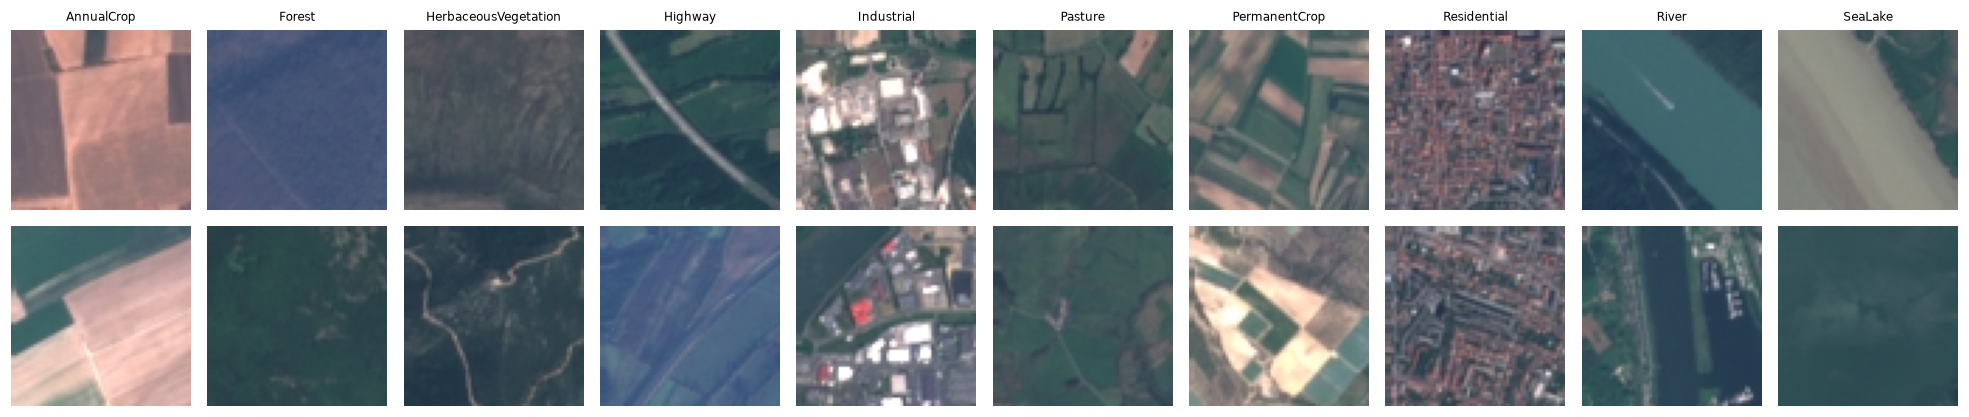

In [2]:
zf = zipfile.ZipFile(EUROSAT)  # the archive
files = [n for n in zf.namelist() if n.endswith(".jpg")]  # every image
cls = np.array([n.split("/")[1] for n in files])  # class from the folder name
CLASSES = sorted(PHRASES)  # the 10 classes
rng = np.random.default_rng(SEED)  # random generator
test_files, pool_files = [], []  # test set and training pool
for c in CLASSES:  # balanced sampling per class
    idx = rng.permutation(np.flatnonzero(cls == c))  # shuffled images of class c
    test_files += [files[i] for i in idx[:100]]; pool_files += [files[i] for i in idx[100:200]]  # 100 test, 100 pool
load = lambda names: [Image.open(zf.open(n)).convert("RGB") for n in names]  # read images
test_img, pool_img = load(test_files), load(pool_files)  # PIL images
y_test = np.array([n.split("/")[1] for n in test_files]); y_pool = np.array([n.split("/")[1] for n in pool_files])  # labels
print(len(files), "images in", len(CLASSES), "classes |", len(test_img), "test |", len(pool_img), "pool | size", test_img[0].size)  # summary

fig, ax = plt.subplots(2, 10, figsize=(18, 4))  # two examples per class
for j, c in enumerate(CLASSES):  # every class
    for i in range(2):  # two examples
        ax[i, j].imshow(test_img[CLASSES.index(c) * 100 + i]); ax[i, j].axis("off")  # one image
    ax[0, j].set_title(c, fontsize=8)  # class name
plt.tight_layout(); plt.show()  # draw

## Zero-shot classification

`fm.zero_shot_classify` embeds every image and one sentence per class built from a template, and
returns the softmax of the scaled similarities plus the top class. Two models, one template:
"a satellite image of {}." (open_clip first builds the empty network and GeoLattice then loads all 302
weight tensors of the RemoteCLIP or GeoRSCLIP checkpoint into it.)

In [3]:
names = [PHRASES[c] for c in CLASSES]  # class words
to_class = dict(zip(names, CLASSES))  # words -> EuroSAT class
zs, t0 = {}, time.perf_counter()  # results and timing
for model in ["remoteclip-vit-b-32", "georsclip-vit-b-32"]:  # two remote sensing CLIPs
    df = fm.zero_shot_classify(test_img, names, model=model, template="a satellite image of {}.", device=DEVICE)  # zero-shot
    zs[model] = df["prediction"].map(to_class).values  # predicted classes
print(f"{time.perf_counter() - t0:.1f} s for {2 * len(test_img)} images")  # timing
acc = pd.DataFrame({m: pd.Series(p == y_test).groupby(y_test).mean() for m, p in zs.items()})  # accuracy per class
acc.loc["overall"] = [np.mean(p == y_test) for p in zs.values()]  # overall accuracy
acc.round(2)

10.5 s for 2000 images


,remoteclip-vit-b-32,georsclip-vit-b-32
AnnualCrop,0.56,0.12
Forest,0.03,0.36
HerbaceousVegetation,0.59,0.18
Highway,0.52,0.95
Industrial,0.10,0.42
Pasture,0.01,0.32
PermanentCrop,0.00,0.08
Residential,0.17,0.99
River,0.73,0.48
SeaLake,0.88,0.98


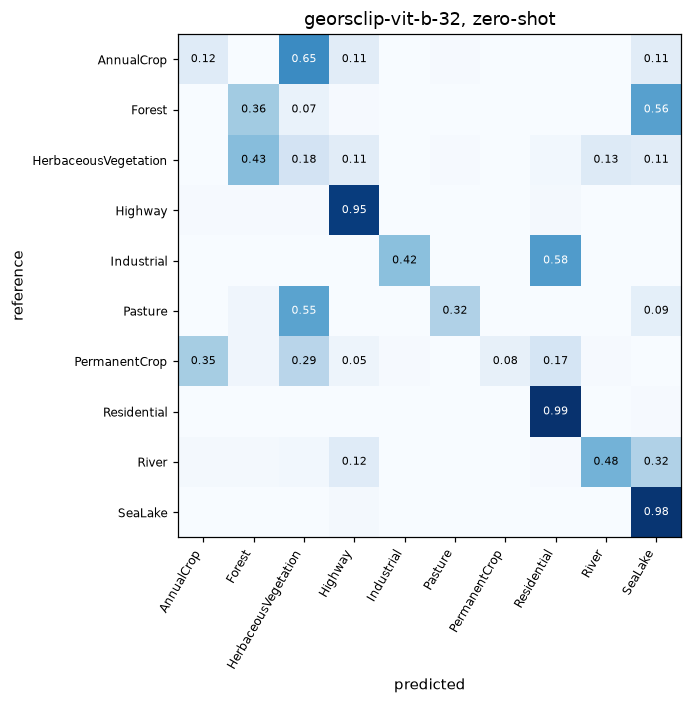

In [4]:
best = acc.loc["overall"].idxmax()  # the better model
cm = confusion_matrix(y_test, zs[best], labels=CLASSES, normalize="true")  # row-normalized confusions
fig, ax = plt.subplots(figsize=(7.5, 6.5))  # one panel
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)  # matrix
ax.set_xticks(range(10), CLASSES, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(10), CLASSES, fontsize=8)  # labels
for (i, j), v in np.ndenumerate(cm):  # write the shares
    if v >= 0.05:  # skip tiny values
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")  # value
ax.set_xlabel("predicted"); ax.set_ylabel("reference"); ax.set_title(f"{best}, zero-shot"); plt.tight_layout(); plt.show()  # draw

GeoRSCLIP (about 49 % overall) beats RemoteCLIP (about 36 %, close to the figure its authors report
for EuroSAT with this encoder), and both are far from the 95 % or more that supervised networks reach
on EuroSAT. The matrix shows where GeoRSCLIP fails. It recognises residential areas, highways and
water bodies almost perfectly, the classes with a distinctive look and many captions. It confuses
classes defined by **use** rather than appearance: annual cropland and pasture go to herbaceous
vegetation, permanent crops (orchards, vineyards) to annual crops, industrial to residential. Dark,
uniform forest patches go to "sea or lake". EuroSAT images are only 64 pixels and are upsampled to
224, so they are much blurrier than the captioned images these models learned from.

## Prompt wording and ensembling

The image and text encoders are loaded once with `fm.load_model`, so many prompts can be tried
without re-embedding the images. Each template is scored alone, then all templates are averaged
(prompt ensembling).

In [5]:
clip = fm.load_model("remoteclip-vit-b-32", device=DEVICE)  # RemoteCLIP: image and text encoders
pre, tok = clip.extras["preprocess"], clip.extras["tokenizer"]  # image preprocessing and tokenizer


def image_emb(images, batch=128):  # unit-length image embeddings
    out = []  # batches
    for i in range(0, len(images), batch):  # in batches
        x = torch.stack([pre(im) for im in images[i:i + batch]])  # preprocessed tensors
        out.append(clip.encode(x).float().cpu().numpy())  # image embeddings
    E = np.concatenate(out)  # all images
    return E / np.linalg.norm(E, axis=1, keepdims=True)  # normalize


def text_emb(sentences):  # unit-length text embeddings
    with torch.no_grad():  # inference
        t = clip.model.encode_text(tok(sentences).to(clip.device)).float().cpu().numpy()  # text embeddings
    return t / np.linalg.norm(t, axis=1, keepdims=True)  # normalize


E_test = image_emb(test_img)  # test images, once
TEMPLATES = ["{}", "a satellite image of {}.", "an aerial photo of {}.", "a remote sensing image of {}.",
             "a low resolution satellite image showing {}.", "a Sentinel-2 image of {}."]  # prompt templates
scores, T_all = {}, []  # accuracies and text embeddings
for t in TEMPLATES:  # every template
    T = text_emb([t.format(n) for n in names])  # one sentence per class
    T_all.append(T)  # keep for ensembling
    scores[t] = np.mean(np.array(CLASSES)[(E_test @ T.T).argmax(1)] == y_test)  # accuracy
ens = np.mean(T_all, 0); ens /= np.linalg.norm(ens, axis=1, keepdims=True)  # averaged class embeddings
scores["ensemble of all templates"] = np.mean(np.array(CLASSES)[(E_test @ ens.T).argmax(1)] == y_test)  # ensemble accuracy
pd.Series(scores, name="accuracy").round(3).to_frame()  # template effects

,accuracy
{},0.300
a satellite image of {}.,0.359
an aerial photo of {}.,0.344
a remote sensing image of {}.,0.327
a low resolution satellite image showing {}.,0.331
a Sentinel-2 image of {}.,0.341
ensemble of all templates,0.326


The bare class words are the worst prompt and "a satellite image of {}." the best, a spread of six
points from wording alone. Averaging all templates does not help here: it lands between the best and
the worst single template. Prompt ensembling usually helps when templates are diverse and individually
decent; it cannot fix a class whose words the model has not linked to its appearance.

## How many labels beat zero-shot?

The same image embeddings feed a logistic regression trained on k labelled images per class from the
pool, for k from 1 to 100. Each k is repeated five times with different draws.

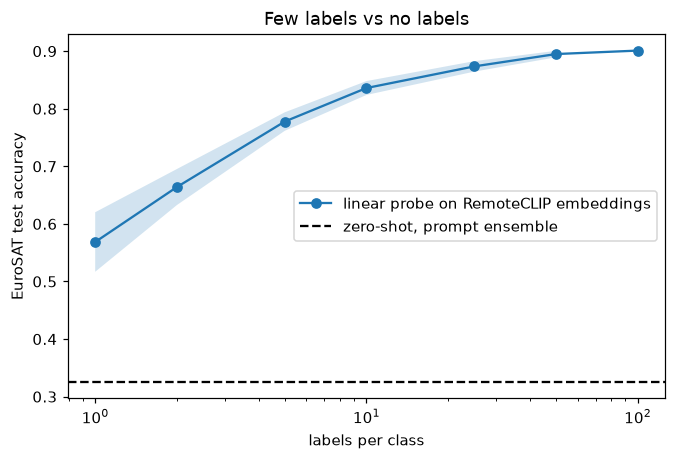

,mean,std
labels per class,,
1,0.569,0.052
2,0.664,0.031
5,0.778,0.016
10,0.836,0.012
25,0.874,0.009
50,0.895,0.006
100,0.901,NaN


In [6]:
from sklearn.linear_model import LogisticRegression  # few-shot classifier

E_pool = image_emb(pool_img)  # pool embeddings
rows = []  # few-shot results
for k in [1, 2, 5, 10, 25, 50, 100]:  # labels per class
    for rep in range(5 if k < 100 else 1):  # repeated draws
        r = np.random.default_rng(rep)  # draw generator
        idx = np.concatenate([r.choice(np.flatnonzero(y_pool == c), k, replace=False) for c in CLASSES])  # k per class
        clf = LogisticRegression(max_iter=3000, C=10).fit(E_pool[idx], y_pool[idx])  # linear probe
        rows.append({"labels per class": k, "accuracy": np.mean(clf.predict(E_test) == y_test)})  # test accuracy
few = pd.DataFrame(rows).groupby("labels per class")["accuracy"].agg(["mean", "std"])  # mean and spread
ax = few["mean"].plot(marker="o", logx=True, figsize=(7, 4.3), label="linear probe on RemoteCLIP embeddings")  # curve
ax.fill_between(few.index, few["mean"] - few["std"], few["mean"] + few["std"], alpha=0.2)  # spread
ax.axhline(scores["ensemble of all templates"], color="k", ls="--", label="zero-shot, prompt ensemble")  # zero-shot level
ax.set_ylabel("EuroSAT test accuracy"); ax.legend(); ax.set_title("Few labels vs no labels"); plt.show()  # draw
few.round(3)

One labelled image per class already beats zero-shot by a wide margin (about 57 % against 36 %),
ten per class reach about 84 % and a hundred about 90 %. The image embeddings hold far more class
information than the text side can retrieve, which is the practical lesson: zero-shot is for
exploring an archive or for classes with no labels at all, and a handful of labels is worth more than
any prompt.

## Searching an archive with words

DeepGlobe images are 2448 pixels at 50 cm; each of 60 training tiles is cut into 4 x 4 crops of 612
pixels (306 m), giving an archive of 960 crops. Each crop's reference class is the majority class of
its mask when it covers at least half of the crop. Six queries are embedded and the 12 most similar
crops are retrieved for each; precision at 12 is the share of retrieved crops whose reference class
matches the query.

In [7]:
DG_CLASSES = pd.read_csv(DG / "class_dict.csv")  # class colours
meta = pd.read_csv(DG / "metadata.csv").query("split == 'train'")  # tiles with masks
tiles = meta.sample(60, random_state=SEED)  # 60 random tiles
crops, crop_cls = [], []  # archive images and reference classes
rgb2cls = {tuple(r[["r", "g", "b"]]): r["name"] for _, r in DG_CLASSES.iterrows()}  # mask colour -> class
for _, t in tiles.iterrows():  # every tile
    im = Image.open(DG / t["sat_image_path"]).convert("RGB")  # image
    mk = (np.asarray(Image.open(DG / t["mask_path"]).convert("RGB")) > 128).astype(int) * 255  # mask, clean colours
    for r in range(4):  # 4 x 4 crops
        for c in range(4):  # columns
            box = (c * 612, r * 612, (c + 1) * 612, (r + 1) * 612)  # crop window
            crops.append(im.crop(box).resize((224, 224)))  # resized crop
            sub = mk[box[1]:box[3], box[0]:box[2]].reshape(-1, 3)  # its mask pixels
            names_px, n = np.unique([rgb2cls.get(tuple(p), "unknown") for p in sub[::97]], return_counts=True)  # sampled classes
            crop_cls.append(names_px[n.argmax()] if n.max() >= 0.5 * n.sum() else "mixed")  # majority or mixed
crop_cls = np.array(crop_cls)  # reference classes
E_dg = image_emb(crops)  # archive embeddings
print(len(crops), "crops |", pd.Series(crop_cls).value_counts().to_dict())  # archive summary

960 crops | {'agriculture_land': 636, 'urban_land': 92, 'forest_land': 73, 'barren_land': 58, 'rangeland': 51, 'water': 33, 'mixed': 17}


                  precision at 12  share of archive (random)
water                        0.08                       0.03
forest_land                  0.50                       0.08
urban_land                   0.83                       0.10
agriculture_land             1.00                       0.66
barren_land                  0.25                       0.06
rangeland                    0.00                       0.05


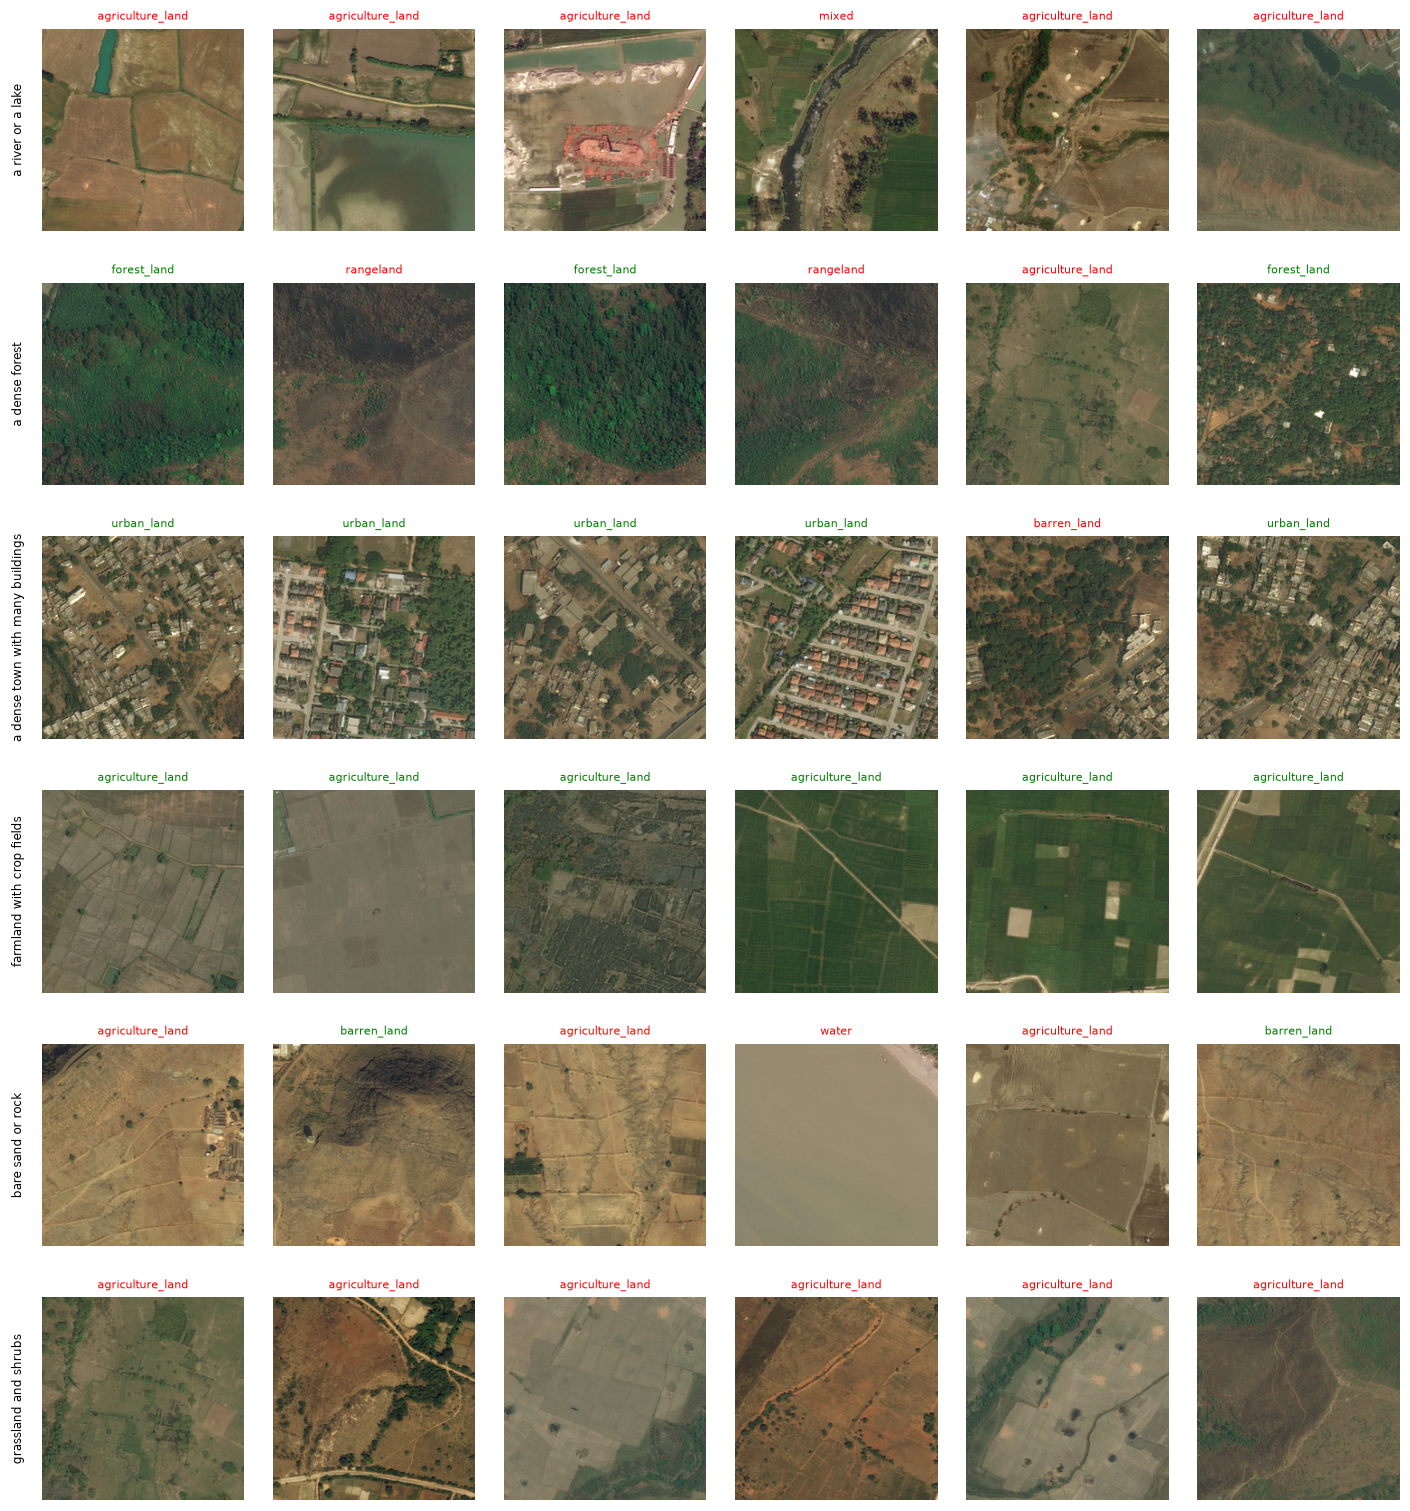

In [8]:
QUERIES = {"water": "a satellite image of a river or a lake", "forest_land": "a satellite image of a dense forest",
           "urban_land": "a satellite image of a dense town with many buildings",
           "agriculture_land": "a satellite image of farmland with crop fields",
           "barren_land": "a satellite image of bare sand or rock", "rangeland": "a satellite image of grassland and shrubs"}  # text queries
Q = text_emb(list(QUERIES.values()))  # query embeddings
idx, sim = fm.embedding_search(E_dg, Q, k=12)  # top 12 crops per query
prec = {c: np.mean(crop_cls[idx[i]] == c) for i, c in enumerate(QUERIES)}  # precision at 12
base = {c: np.mean(crop_cls == c) for c in QUERIES}  # random retrieval
print(pd.DataFrame({"precision at 12": prec, "share of archive (random)": base}).round(2))  # scores
fig, ax = plt.subplots(len(QUERIES), 6, figsize=(13, 2.3 * len(QUERIES)))  # top 6 per query
for i, (c, q) in enumerate(QUERIES.items()):  # every query
    for j in range(6):  # top hits
        ax[i, j].imshow(crops[idx[i, j]]); ax[i, j].axis("off")  # hit
        ax[i, j].set_title(crop_cls[idx[i, j]], fontsize=7, color="green" if crop_cls[idx[i, j]] == c else "red")  # its class
    ax[i, 0].text(-20, 112, q.replace("a satellite image of ", ""), rotation=90, va="center", ha="right", fontsize=8)  # query
plt.tight_layout(); plt.show()  # draw

Text search works for classes with a distinctive look. "A dense town" returns urban crops for 10 of
12 hits against 10 % urban crops in the archive, and "a dense forest" returns forest for half its
hits against 8 %. It fails for the rest. The water query returns fields with small ponds and canals,
because only 33 crops are mostly water at 306 m. The rangeland query returns nothing labelled
rangeland: in DeepGlobe rangeland is defined by use and looks like fallow fields. Agriculture
reaches 100 %, but two thirds of the archive is agriculture, so that score means little. Precision
must always be read against the share of the class in the archive.

## Searching with an example image

An image can be the query too. Here the queries are EuroSAT images (10 m Sentinel-2) and the archive
is DeepGlobe (50 cm): a 20 times difference in resolution.

In [9]:
rows = []  # cross-dataset image queries
pairs = {"River": "water", "Forest": "forest_land", "Residential": "urban_land", "AnnualCrop": "agriculture_land"}  # EuroSAT -> DeepGlobe
for es, dg in pairs.items():  # every pair
    q = E_test[y_test == es][:20]  # 20 EuroSAT examples of the class
    ii, _ = fm.embedding_search(E_dg, q.mean(0, keepdims=True), k=12)  # search with their mean embedding
    rows.append({"EuroSAT query": es, "DeepGlobe class": dg, "precision at 12": np.mean(crop_cls[ii[0]] == dg),
                 "share of archive": np.mean(crop_cls == dg)})  # scores
pd.DataFrame(rows).round(2)

,EuroSAT query,DeepGlobe class,precision at 12,share of archive
0,River,water,0.58,0.03
1,Forest,forest_land,0.00,0.08
2,Residential,urban_land,0.75,0.10
3,AnnualCrop,agriculture_land,0.92,0.66


Image queries do better than text for water (58 % against 8 % with words) and almost as well for
towns, even though the queries are 10 m Sentinel-2 images and the archive is 50 cm imagery. They fail
completely for forest. A 10 m forest is a smooth dark green texture, while a 50 cm forest shows
individual crowns, so at twenty times the resolution the two no longer look alike to the encoder.

## What vision-language models cannot do

A short test of three requests the models are often asked to do: count objects, read infrared, and
use place names. Each is scored on images whose answer is known.

In [10]:
# 1. Counting: the probability given to "one", "two" or "many" buildings follows texture, not counts
cnt = text_emb([f"a satellite image with {w} buildings" for w in ["one", "two", "three", "many"]])  # counting prompts
res = E_test[y_test == "Residential"][:50] @ cnt.T  # residential images vs the prompts
print("residential images, chosen count prompt:", pd.Series(np.array(["one", "two", "three", "many"])[res.argmax(1)]).value_counts().to_dict())  # answers

# 2. False colour: the same images shown as NIR-red-green would need infrared bands the model never saw
print("RemoteCLIP input:", fm.model_info("remoteclip-vit-b-32")["inputs"])  # RGB only

# 3. Place names: the same forest images described with two countries
pl = text_emb(["a satellite image of a forest in Germany", "a satellite image of a forest in Brazil"])  # place prompts
f_img = E_test[y_test == "Forest"]  # European forest images
print("European forests matched to 'Germany' vs 'Brazil':", np.bincount((f_img @ pl.T).argmax(1), minlength=2))  # place answer

residential images, chosen count prompt: {'many': 31, 'one': 19}
RemoteCLIP input: RGB 224 px + text
European forests matched to 'Germany' vs 'Brazil': [100   0]


- **Counting.** Every residential image contains dozens of buildings, yet 19 of 50 were matched to
  "one building". The similarity follows texture and brightness, not the number of objects.
- **Bands.** The models take RGB only; infrared, the most informative part of the spectrum for
  vegetation and water, never reaches them.
- **Places.** All 100 forest images were matched to "Germany" rather than "Brazil". That looks
  right, but it reflects a learned link between temperate texture and the word, not geolocation: the
  images come from 34 countries, and none of them is Germany-specific. A place name in a prompt is a
  stylistic cue, never a location check.

## Summary and exercises

### Summary

- CLIP-style models embed images and sentences in one space; zero-shot classification picks the class
  whose sentence is most similar to the image.
- On EuroSAT, remote sensing CLIPs classify some classes well and confuse others that differ by use
  rather than appearance; every result needs a reference check.
- Prompt wording changes accuracy; averaging several templates is a cheap improvement.
- A linear probe on the same image embeddings overtakes zero-shot with a handful of labels per class.
- Text search works for visually distinctive classes; image queries work even across a twentyfold
  change in resolution for some classes.
- Counting, non-RGB bands and place names are outside what these models do reliably.

### Exercises

1. Write three alternative phrasings for the two worst classes and find the best one. Is it still best
   with GeoRSCLIP?
2. Use `remoteclip-vit-l-14` (download about 1.7 GB). Does a larger encoder fix the confusions?
3. Repeat the few-shot curve with GeoRSCLIP embeddings and with the SSL4EO ResNet-18 on the same RGB
   images. Which representation is most label-efficient?
4. Add the query "a satellite image of a road" to the DeepGlobe search. Which class do the hits belong
   to, and why is the precision hard to define?
5. Re-run zero-shot on EuroSAT images upsampled from 64 to 224 pixels with nearest neighbour instead of
   bicubic resampling. Does the interpolation matter?

### References

- Helber, P. et al. (2019). EuroSAT: a novel dataset and deep learning benchmark for land use and land cover classification. IEEE JSTARS.
- Demir, I. et al. (2018). DeepGlobe 2018: a challenge to parse the Earth through satellite images. CVPR Workshops.
- Liu, F. et al. (2024). RemoteCLIP: a vision language foundation model for remote sensing. IEEE TGRS.
- Radford, A. et al. (2021). Learning transferable visual models from natural language supervision (CLIP). ICML.
- Wang, Z. et al. (2024). SkyScript: a large and semantically diverse vision-language dataset for remote sensing. AAAI.
- Zhang, Z. et al. (2024). RS5M and GeoRSCLIP: a large scale vision-language dataset and a large vision-language model for remote sensing. IEEE TGRS.